# Prepare environment

In [1]:
%reload_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

# Load data

In [4]:
import json
import os

from src.dataset import get_data_loaders

cfg_path = "../cfg.json"
print(f"Loading configuration from {cfg_path}")
with open(cfg_path, "r") as f:
    cfg = json.load(f)

data_dir = os.path.join("../", cfg["data"]["dir"])
batch_size = cfg["data"]["batch_size"]
num_workers = cfg["data"]["num_workers"]
train_ratio = cfg["data"]["train_ratio"]
train_dataloader, valid_dataloader, test_dataloader = get_data_loaders(data_dir, train_ratio, batch_size, num_workers)

Loading configuration from ../cfg.json
Data configuration:
Data directory: ../data/
Batch size: 32
Number of workers: 0
Train ratio: 0.9
Saved processed training data to ../data/train.pt
Saved processed test data to ../data/test.pt
Train dataset size: 37800
Validation dataset size: 4200
Test dataset size: 28000


# Visualize a data sample

In [ ]:
import torch

from src.model import CNN_FC as DigitClassifier
from src import trainer

model = DigitClassifier(
    cfg["model"]["architecture"]["feature_size"],
    cfg["model"]["architecture"]["feature_map_sizes"],
    cfg["model"]["architecture"]["conv_kernel_sizes"],
    cfg["model"]["architecture"]["pool_kernel_sizes"],
    cfg["model"]["architecture"]["pool_strides"],
    cfg["model"]["architecture"]["fc_sizes"]
)

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=cfg["train"]["learning_rate"],
    momentum=cfg["train"]["momentum"]
)

loss_fn = torch.nn.functional.cross_entropy

lrs = torch.logspace(-4, -0.8, 200).tolist()
batch_iter = iter(train_dataloader)

model.train(True)
used_lrs = []
losses = []
for lr in lrs:
    try:
        batch = next(batch_iter)
    except StopIteration:
        break

    for g in optimizer.param_groups:
        g['lr'] = lr
    
    loss = trainer.train_one_batch(model, optimizer, loss_fn, batch)

    if not torch.isfinite(loss):
        break

    used_lrs.append(lr)
    losses.append(loss.detach().item())

    

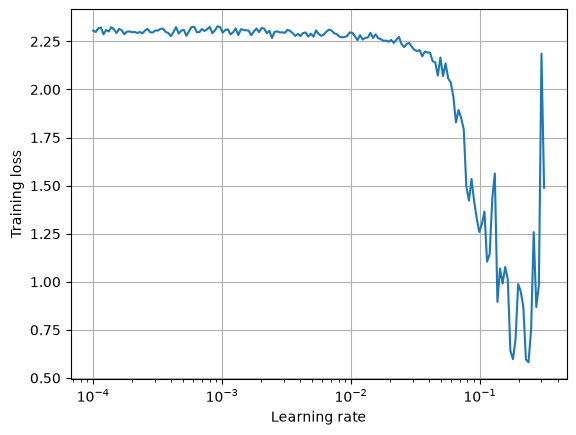

In [97]:
%matplotlib inline

import matplotlib.pyplot as plt

plt.plot(used_lrs, losses)
plt.xscale("log")
plt.xlabel("Learning rate")
plt.ylabel("Training loss")
plt.grid(True)